#### Activity 7 Finding of Natural of Citizen (Unsupervised)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#1. Generate realistic data for Indian districts
np.random.seed(42)
n_districts = 150
# Three natural groups (e.g., Metro Hubs, Tier-2 Developing, Remote/Lagging)

group1_lit = np.random.normal(85, 5, 60)
group1_srv = np.random.normal(90, 6, 60)

group2_lit = np.random.normal (65, 6, 50)
group2_srv = np.random.normal(55, 7, 50)

group3_lit = np.random.normal(45, 5, 40)
group3_srv = np.random.normal(30, 5, 40)

literacy_rate = np.concatenate ([group1_lit, group2_lit, group3_lit])
service_usage = np.concatenate ([group1_srv, group2_srv, group3_srv])

In [3]:
df_districts = pd.DataFrame({
    'District_Name': [f"District_(i+1)" for i in range(n_districts)],
    'Digital_Literacy_Pct': np.clip(literacy_rate, 20, 100).round(1),
    'E_Governance_Usage_Pct': np.clip(service_usage, 10, 100).round(1)
})

In [4]:
df = df_districts.copy()
df.head()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct
0,District_(i+1),87.5,87.1
1,District_(i+1),84.3,88.9
2,District_(i+1),88.2,83.4
3,District_(i+1),92.6,82.8
4,District_(i+1),83.8,94.9


In [5]:
print(df.info())
print() 
print(df.describe())
print()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   District_Name           150 non-null    object 
 1   Digital_Literacy_Pct    150 non-null    float64
 2   E_Governance_Usage_Pct  150 non-null    float64
dtypes: float64(2), object(1)
memory usage: 3.6+ KB
None

       Digital_Literacy_Pct  E_Governance_Usage_Pct
count            150.000000              150.000000
mean              67.489333               62.530667
std               16.595488               25.331266
min               34.900000               13.800000
25%               55.450000               37.975000
50%               68.300000               58.750000
75%               82.700000               88.675000
max               94.300000              100.000000

District_Name             0
Digital_Literacy_Pct      0
E_Governance_Usage_Pct    0
dtype: int64


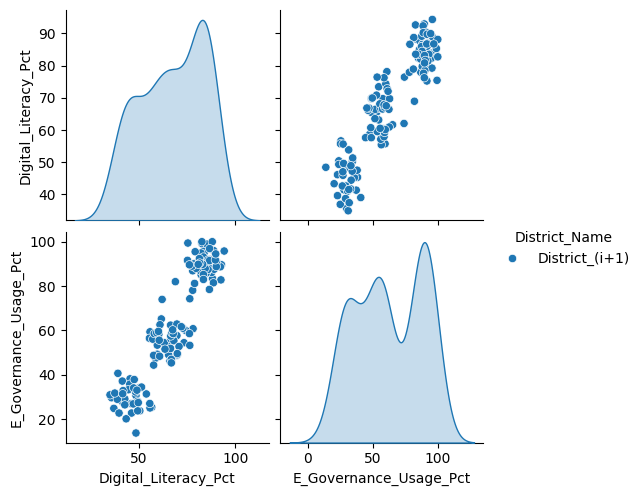

In [6]:
sns.pairplot(df, vars=["Digital_Literacy_Pct", "E_Governance_Usage_Pct"], hue="District_Name", palette="tab10")

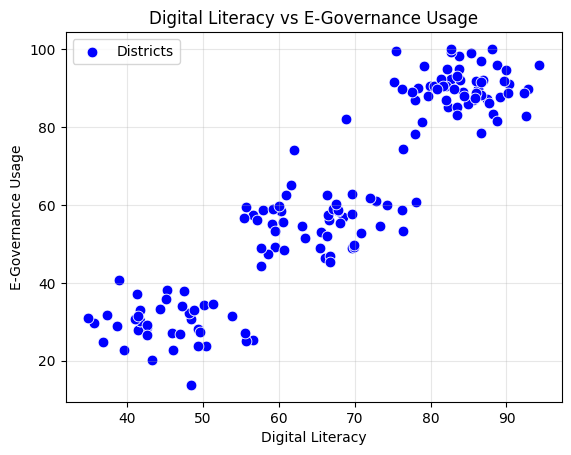

In [7]:
sns.scatterplot(
    data=df,
    x="Digital_Literacy_Pct",
    y="E_Governance_Usage_Pct",
    color="blue",
    label="Districts",
    s=60
)

plt.xlabel("Digital Literacy")
plt.ylabel("E-Governance Usage")
plt.title("Digital Literacy vs E-Governance Usage")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [8]:
from sklearn.cluster import KMeans

X = df[["Digital_Literacy_Pct", "E_Governance_Usage_Pct"]]

model = KMeans(n_clusters=3, random_state=42, n_init=10)

df["Cluster"] = model.fit_predict(X)
df.head()

,District_Name,Digital_Literacy_Pct,E_Governance_Usage_Pct,Cluster
0,District_(i+1),87.5,87.1,0
1,District_(i+1),84.3,88.9,0
2,District_(i+1),88.2,83.4,0
3,District_(i+1),92.6,82.8,0
4,District_(i+1),83.8,94.9,0


In [9]:
model

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [10]:
model.cluster_centers_

array([[83.97868852, 89.74590164],
       [45.1975    , 29.5425    ],
       [65.15918367, 55.57959184]])

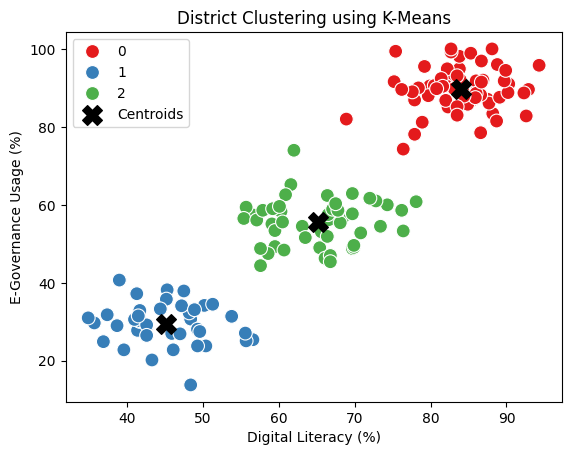

In [11]:
sns.scatterplot(
    data=df,
    x="Digital_Literacy_Pct",
    y="E_Governance_Usage_Pct",
    hue="Cluster",
    palette="Set1",
    s=100,
)

centroids = model.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    color="black",
    s=200,
    label="Centroids"
)

plt.xlabel("Digital Literacy (%)")
plt.ylabel("E-Governance Usage (%)")
plt.title("District Clustering using K-Means")
plt.legend()
plt.show()

In [12]:
new_data = pd.DataFrame(
    [[25, 35],
     [55, 70],
     [90, 85],
     [45, 50],
     [95, 98]],
    columns=[
        "Digital_Literacy_Pct",
        "E_Governance_Usage_Pct"
    ]
)

new_data["Cluster"] = model.predict(new_data)

print(new_data)

   Digital_Literacy_Pct  E_Governance_Usage_Pct  Cluster
0                    25                      35        1
1                    55                      70        2
2                    90                      85        0
3                    45                      50        1
4                    95                      98        0


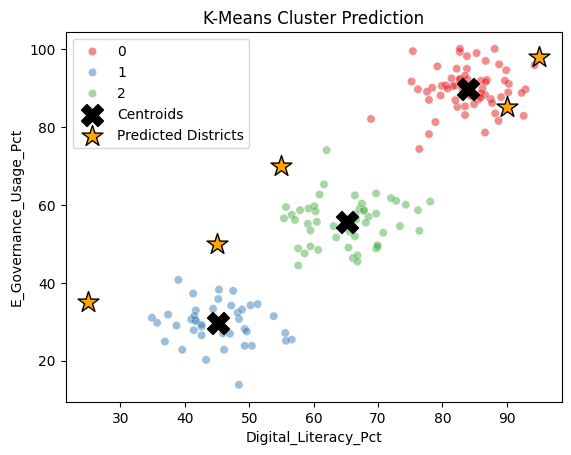

In [13]:
sns.scatterplot(
    data=df,
    x="Digital_Literacy_Pct",
    y="E_Governance_Usage_Pct",
    hue="Cluster",
    palette="Set1",
    alpha=0.5
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="black",
    marker="X",
    s=250,
    label="Centroids"
)

plt.scatter(
    new_data["Digital_Literacy_Pct"],
    new_data["E_Governance_Usage_Pct"],
    color="orange",
    marker="*",
    s=250,
    edgecolors="black",
    label="Predicted Districts"
)

plt.title("K-Means Cluster Prediction")
plt.legend()
plt.show()

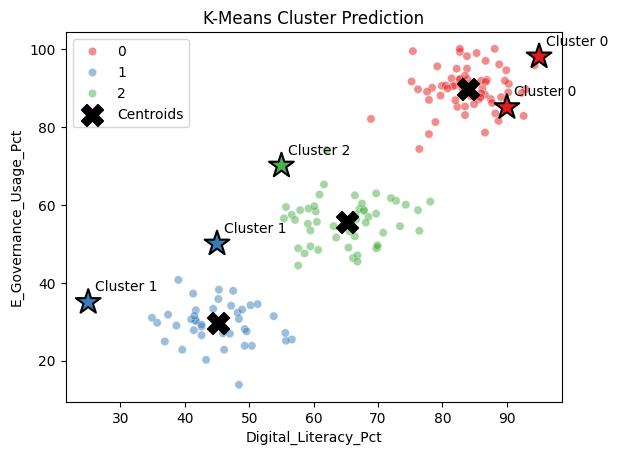

In [14]:
# Existing clusters
sns.scatterplot(
    data=df,
    x="Digital_Literacy_Pct",
    y="E_Governance_Usage_Pct",
    hue="Cluster",
    palette="Set1",
    alpha=0.5
)

# Cluster centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="black",
    marker="X",
    s=250,
    label="Centroids"
)

# Predicted districts with respective cluster colors
sns.scatterplot(
    data=new_data,
    x="Digital_Literacy_Pct",
    y="E_Governance_Usage_Pct",
    hue="Cluster",
    palette="Set1",
    hue_order=sorted(df["Cluster"].unique()),
    marker="*",
    s=350,
    edgecolor="black",
    legend=False
)

# Display predicted cluster IDs
for _, row in new_data.iterrows():
    plt.annotate(
        f"Cluster {int(row['Cluster'])}",
        (row["Digital_Literacy_Pct"],
         row["E_Governance_Usage_Pct"]),
        xytext=(5,8),
        textcoords="offset points"
    )

plt.title("K-Means Cluster Prediction")
plt.legend()
plt.show()

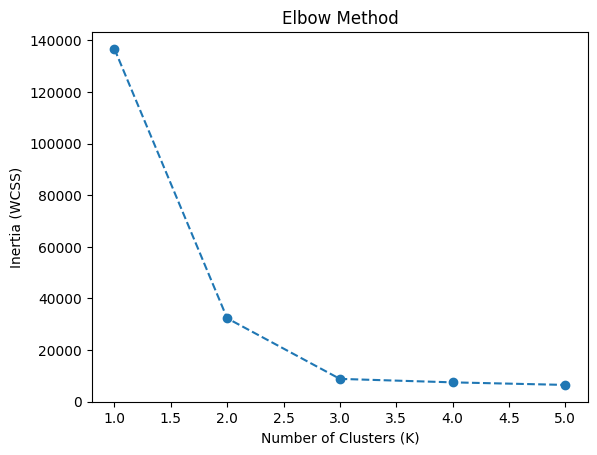

In [15]:
inertia = []
K = range(1, 6)

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(K, inertia, marker="o", linestyle="--")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.show()